In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import kaggle
from kaggle.api.kaggle_api_extended import KaggleApi
from scipy import stats
from scipy.stats import chi2_contingency

# Configura las variables de entorno para la API
os.environ['KAGGLE_CONFIG_DIR'] = r'C:\Usuarios\Usuario\.kaggle'

# Inicializa y autentica la API de Kaggle
api = KaggleApi()
api.authenticate()

# Descarga el dataset (esto crea un ZIP en la carpeta actual)
api.dataset_download_files('asaniczka/uk-optimal-product-price-prediction', path='.', unzip=True)

df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

df.head()

# Opcional: formateo de gráficos
sns.set_theme(style="whitegrid")

Dataset URL: https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction


In [4]:
df["category"].astype("category") 
print(df["isBestSeller"].dtype)
# Asegura tipos numéricos
for col in ["price", "stars", "reviews", "boughtInLastMonth"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Limpieza básica
df = df.dropna(subset=["price", "stars", "category"])  # imprescindible para este lab

bool


In [5]:
# Tabla de contingencia
ct = pd.crosstab(df["category"], df["isBestSeller"], dropna=False)

# Proporción de best-sellers por categoría
prop_best = (ct[True] / ct.sum(axis=1)).sort_values(ascending=False)
prop_best.name = "prop_best_seller"

# Añade conteo total para filtrar categorías muy pequeñas si quieres (ruido)
summary_best = pd.concat([ct.sum(axis=1).rename("n"), prop_best], axis=1).sort_values("prop_best_seller", ascending=False)

display(summary_best.head(20))


,n,prop_best_seller
category,,
Grocery,9564,0.058135
Smart Home Security & Lighting,104,0.057692
Health & Personal Care,9569,0.057686
Mobile Phone Accessories,259,0.042471
Power & Hand Tools,8659,0.035339
"Billiard, Snooker & Pool",249,0.032129
Pet Supplies,9437,0.030200
Home Brewing & Wine Making,246,0.028455
Mirrors,250,0.028000


In [6]:
# Chi-cuadrado
chi2, p, dof, expected = chi2_contingency(ct.values)
n = ct.values.sum()
k = min(ct.shape)  # min(n_filas, n_cols)

# Cramér's V
cramers_v = np.sqrt(chi2 / (n * (k - 1)))

print(f"Chi2={chi2:,.2f} | dof={dof} | p-value={p:.4g}")
print(f"Cramér's V={cramers_v:.4f} (0: sin asociación, 1: fuerte)")

# Nota: con tamaños de muestra enormes, p<<0.05 es común; céntrate en el tamaño del efecto (Cramér's V).


Chi2=36,540.20 | dof=295 | p-value=0
Cramér's V=0.1223 (0: sin asociación, 1: fuerte)


In [ ]:
# Conclusión de Negocio: Best-sellers por categoría: la proporción de best-sellers no es uniforme; el test de Chi-cuadrado rechaza independencia (p ≪ 0.05), 
# pero Cramér’s V indica un tamaño de efecto bajo–moderado → la categoría influye, pero no lo explica todo. 
# Priorizar surtido y campañas en categorías con tasa alta y volumen suficiente.

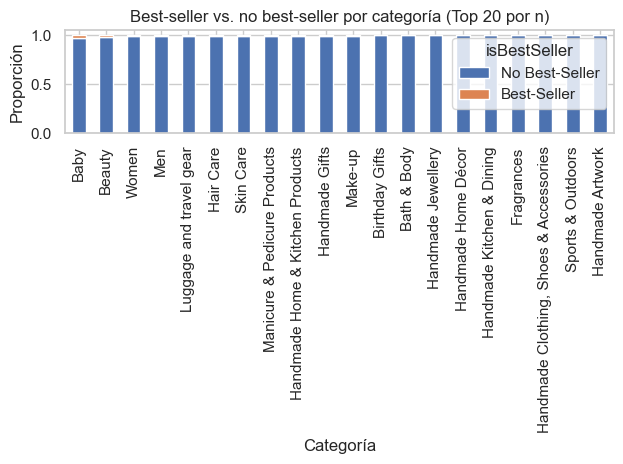

In [7]:
# Para legibilidad, ordena categorías por n y muestra Top N
topN = 20
top_cats = ct.sum(axis=1).sort_values(ascending=False).head(topN).index
ct_top = ct.loc[top_cats]

ct_top_norm = ct_top.div(ct_top.sum(axis=1), axis=0)  # porcentajes por fila

ct_top_norm.sort_values(True, ascending=False).plot(kind="bar", stacked=True)
plt.title(f"Best-seller vs. no best-seller por categoría (Top {topN} por n)")
plt.ylabel("Proporción")
plt.xlabel("Categoría")
plt.legend(["No Best-Seller", "Best-Seller"], title="isBestSeller", loc="upper right")
plt.tight_layout()
plt.show()


In [8]:
# IQR para price
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_no_out = df[(df["price"] >= lower) & (df["price"] <= upper)].copy()
print(f"Tamaño original: {len(df):,} | Sin outliers: {len(df_no_out):,} | % mantenido: {100*len(df_no_out)/len(df):.2f}%")


Tamaño original: 2,443,651 | Sin outliers: 2,115,963 | % mantenido: 86.59%


In [ ]:
# Outliers: distorsionan medias y correlaciones; el análisis “sin outliers” ofrece una imagen más estable. 
# Para reporting, usar mediana/IQR y comparar siempre “con vs sin outliers”.

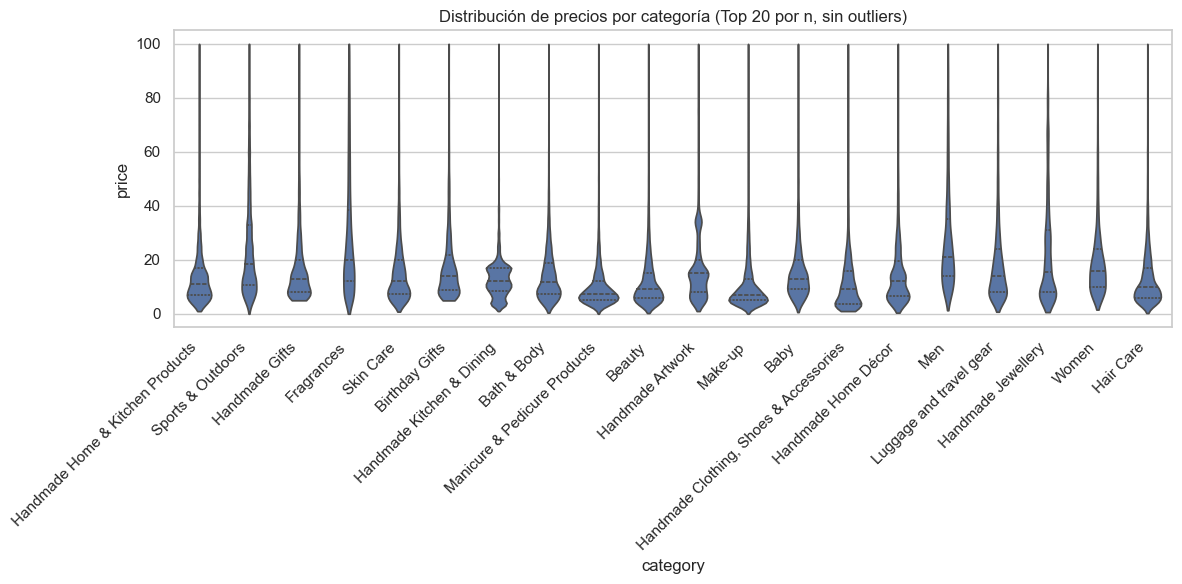

category
Laptops                                1042.725
Desktop PCs                             810.400
Snowboards                              366.725
Home Audio Record Players               326.080
3D Printers                             319.000
Motorbike Exhaust & Exhaust Systems     313.830
Graphics Cards                          259.980
Snowboard Boots                         258.990
Lenses                                  249.990
Barebone PCs                            244.990
Name: price, dtype: float64

Categoría con mayor mediana (sin filtrar top): Laptops 1042.725


In [9]:
# Filtra Top 20 categorías por conteo
top20 = df_no_out["category"].value_counts().head(20).index
df_vio = df_no_out[df_no_out["category"].isin(top20)].copy()

plt.figure(figsize=(12,6))
sns.violinplot(data=df_vio, x="category", y="price", inner="quartile", cut=0)
plt.title("Distribución de precios por categoría (Top 20 por n, sin outliers)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# ¿Qué categoría tiene la mayor mediana de precio? (sin filtrar por Top N)
median_by_cat = df.groupby("category")["price"].median().sort_values(ascending=False)
display(median_by_cat.head(10))
print("Categoría con mayor mediana (sin filtrar top):", median_by_cat.index[0], median_by_cat.iloc[0])


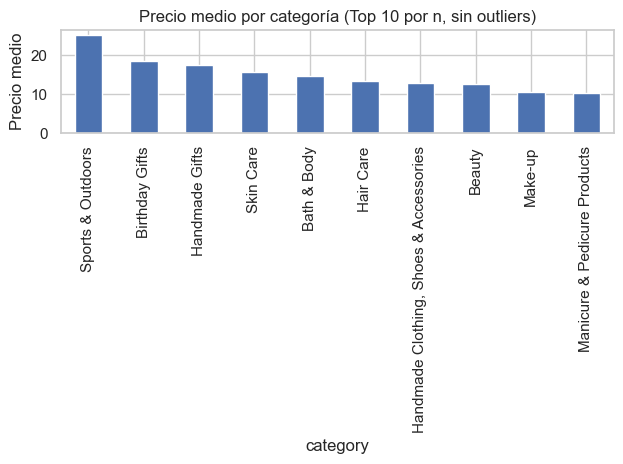

category
Laptops                       1087.987827
3D Printers                   1018.036129
Desktop PCs                    926.816064
Home Office Furniture          622.135898
Test & Measurement             559.382973
Home Audio Record Players      529.665585
CPUs                           514.519317
Digital Cameras                496.156185
Material Handling Products     487.191813
Graphics Cards                 444.746827
Name: price, dtype: float64

Categoría con mayor precio medio (sin filtrar top): Laptops 1087.987826986755


In [10]:
# Top 10 categorías por conteo -> media de precio (sin outliers)
top10 = df_no_out["category"].value_counts().head(10).index
mean_price_top10 = df_no_out[df_no_out["category"].isin(top10)].groupby("category")["price"].mean().sort_values(ascending=False)

mean_price_top10.plot(kind="bar")
plt.title("Precio medio por categoría (Top 10 por n, sin outliers)")
plt.ylabel("Precio medio")
plt.tight_layout()
plt.show()

# ¿Qué categoría tiene mayor precio medio? (sin filtrar por top; puede ser ruidoso si la categoría es muy pequeña)
mean_by_cat_all = df.groupby("category")["price"].mean().sort_values(ascending=False)
display(mean_by_cat_all.head(10))
print("Categoría con mayor precio medio (sin filtrar top):", mean_by_cat_all.index[0], mean_by_cat_all.iloc[0])


In [17]:
median_by_cat_all = df.groupby("category")["price"].median().sort_values(ascending=False)
display(median_by_cat_all.head(10))
print("Categoría con mayor mediana de precio (global):", median_by_cat_all.index[0], median_by_cat_all.iloc[0])


category
Laptops                                1042.725
Desktop PCs                             810.400
Snowboards                              366.725
Home Audio Record Players               326.080
3D Printers                             319.000
Motorbike Exhaust & Exhaust Systems     313.830
Graphics Cards                          259.980
Snowboard Boots                         258.990
Lenses                                  249.990
Barebone PCs                            244.990
Name: price, dtype: float64

Categoría con mayor mediana de precio (global): Laptops 1042.725


In [18]:
mean_by_cat_all = df.groupby("category").agg(n=("price","size"), mean_price=("price","mean"))
mean_by_cat_all_sorted = mean_by_cat_all.sort_values("mean_price", ascending=False)
display(mean_by_cat_all_sorted.head(10))

# Versión robusta: exigir n mínimo para evitar categorías minúsculas
min_n = 200
mean_by_cat_min = mean_by_cat_all.query("n >= @min_n").sort_values("mean_price", ascending=False)
display(mean_by_cat_min.head(10))

print("Mayor precio medio (global, sin filtro n):", mean_by_cat_all_sorted.index[0], mean_by_cat_all_sorted.iloc[0].mean_price)
print(f"Mayor precio medio (n >= {min_n}):", mean_by_cat_min.index[0], mean_by_cat_min.iloc[0].mean_price)


,n,mean_price
category,,
Laptops,7248,1087.987827
3D Printers,248,1018.036129
Desktop PCs,7395,926.816064
Home Office Furniture,2462,622.135898
Test & Measurement,259,559.382973
Home Audio Record Players,6374,529.665585
CPUs,249,514.519317
Digital Cameras,1489,496.156185
Material Handling Products,160,487.191813


,n,mean_price
category,,
Laptops,7248,1087.987827
3D Printers,248,1018.036129
Desktop PCs,7395,926.816064
Home Office Furniture,2462,622.135898
Test & Measurement,259,559.382973
Home Audio Record Players,6374,529.665585
CPUs,249,514.519317
Digital Cameras,1489,496.156185
Graphics Cards,249,444.746827


Mayor precio medio (global, sin filtro n): Laptops 1087.987826986755
Mayor precio medio (n >= 200): Laptops 1087.987826986755


In [ ]:
# Precios por categoría: la mediana es más representativa que la media (sensibles a outliers). Identificamos categorías de ticket alto
# (mediana y media elevadas); considerar posicionamiento premium y logística adecuada.
# En nuestro caso, la categoría "Laptops" destaca por su mediana y media de precio.

In [19]:
rating_by_cat = df.groupby("category").agg(n=("stars","size"), median_rating=("stars","median"))
rating_by_cat_sorted = rating_by_cat.sort_values("median_rating", ascending=False)
display(rating_by_cat_sorted.head(10))

min_n = 200
rating_by_cat_min = rating_by_cat.query("n >= @min_n").sort_values("median_rating", ascending=False)
display(rating_by_cat_min.head(10))

print("Mayor mediana de rating (global, sin filtro n):", rating_by_cat_sorted.index[0], rating_by_cat_sorted.iloc[0].median_rating)
print(f"Mayor mediana de rating (n >= {min_n}):", rating_by_cat_min.index[0], rating_by_cat_min.iloc[0].median_rating)


,n,median_rating
category,,
Computer Memory,248,4.7
CPUs,249,4.6
Building & Construction Toys,9490,4.6
Laptop Accessories,250,4.6
Hobbies,9174,4.6
Kids' Play Figures,9471,4.6
"Beer, Wine & Spirits",9553,4.6
Office Paper Products,9096,4.6
Luxury Food & Drink,679,4.6


,n,median_rating
category,,
Computer Memory,248,4.7
Building & Construction Toys,9490,4.6
CPUs,249,4.6
"Beer, Wine & Spirits",9553,4.6
Kids' Play Figures,9471,4.6
Office Paper Products,9096,4.6
Hobbies,9174,4.6
Luxury Food & Drink,679,4.6
Laptop Accessories,250,4.6


Mayor mediana de rating (global, sin filtro n): Computer Memory 4.7
Mayor mediana de rating (n >= 200): Computer Memory 4.7


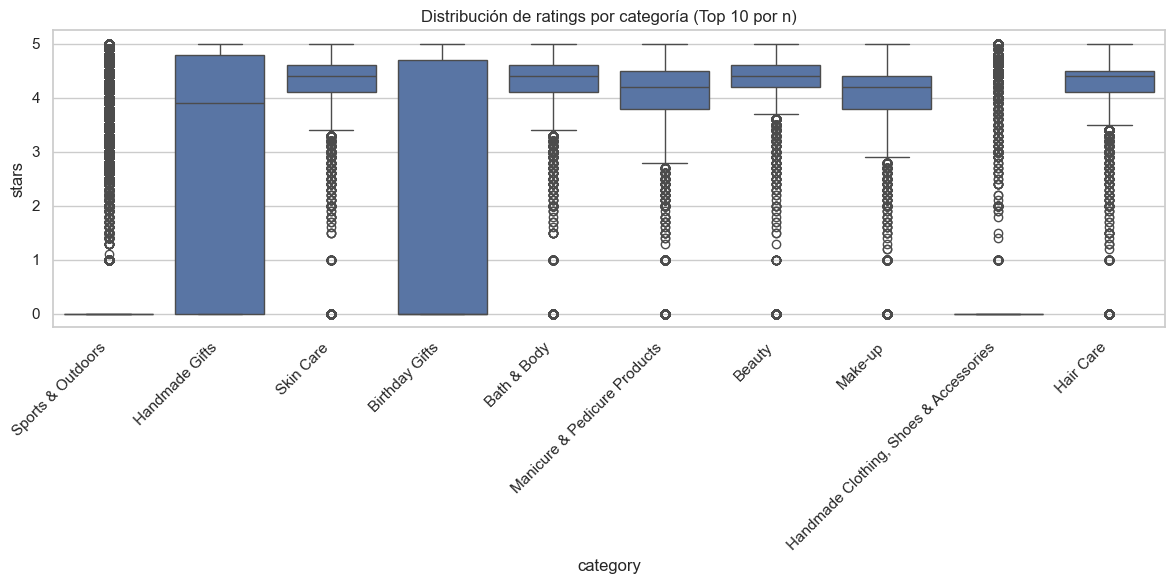

category
Computer Memory                 4.7
CPUs                            4.6
Building & Construction Toys    4.6
Laptop Accessories              4.6
Hobbies                         4.6
Kids' Play Figures              4.6
Beer, Wine & Spirits            4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Children's Bedding              4.5
Name: stars, dtype: float64

Categoría con mayor mediana de rating (sin filtrar top): Computer Memory 4.7


In [11]:
# Boxplots para ratings por categoría (Top 10 por n, sin outliers en price no es relevante aquí, pero nos quedamos con df_no_out por consistencia de subset)
top10_r = df_no_out["category"].value_counts().head(10).index
df_box = df_no_out[df_no_out["category"].isin(top10_r)].copy()

plt.figure(figsize=(12,6))
sns.boxplot(data=df_box, x="category", y="stars")
plt.title("Distribución de ratings por categoría (Top 10 por n)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# ¿Qué categoría tiene mayor mediana de rating? (sin filtrar top)
median_rating_by_cat = df.groupby("category")["stars"].median().sort_values(ascending=False)
display(median_rating_by_cat.head(10))
print("Categoría con mayor mediana de rating (sin filtrar top):", median_rating_by_cat.index[0], median_rating_by_cat.iloc[0])


In [ ]:
# Ratings por categoría: categorías con medianas de rating altas sugieren buena satisfacción; priorizar visibilidad.
# En nuestro caso "Computer Memory" destaca por su mediana de rating.

In [12]:
# Correlaciones (Pearson lineal y Spearman por rangos)
sub = df[["price", "stars"]].dropna().copy()

pearson_r, pearson_p = stats.pearsonr(sub["price"], sub["stars"])
spearman_r, spearman_p = stats.spearmanr(sub["price"], sub["stars"])

print(f"Pearson r={pearson_r:.4f} (p={pearson_p:.2e})")
print(f"Spearman ρ={spearman_r:.4f} (p={spearman_p:.2e})")

# Repite sin outliers (precio)
sub_no = df_no_out[["price", "stars"]].dropna()
pearson_r_no, pearson_p_no = stats.pearsonr(sub_no["price"], sub_no["stars"])
spearman_r_no, spearman_p_no = stats.spearmanr(sub_no["price"], sub_no["stars"])

print(f"[Sin outliers] Pearson r={pearson_r_no:.4f} (p={pearson_p_no:.2e})")
print(f"[Sin outliers] Spearman ρ={spearman_r_no:.4f} (p={spearman_p_no:.2e})")


Pearson r=-0.1249 (p=0.00e+00)
Spearman ρ=-0.1332 (p=0.00e+00)
[Sin outliers] Pearson r=-0.0777 (p=0.00e+00)
[Sin outliers] Spearman ρ=-0.0668 (p=0.00e+00)


In [ ]:
# Precio vs rating: correlación baja (Pearson/Spearman) → el precio no determina la valoración; 
# influyen marca, expectativas, calidad percibida, reviews y servicio.

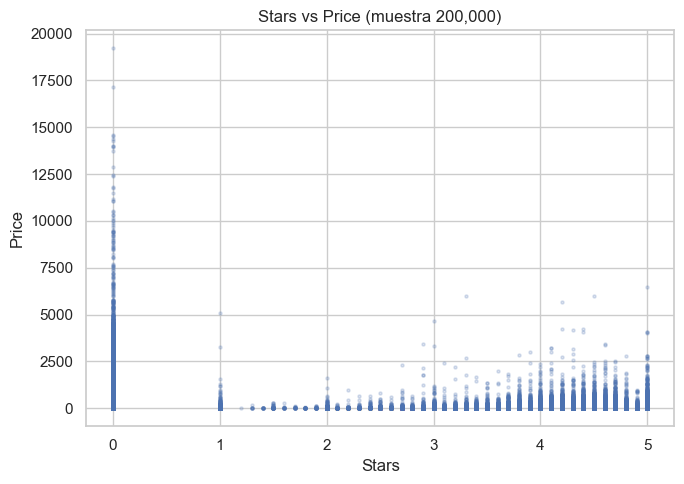

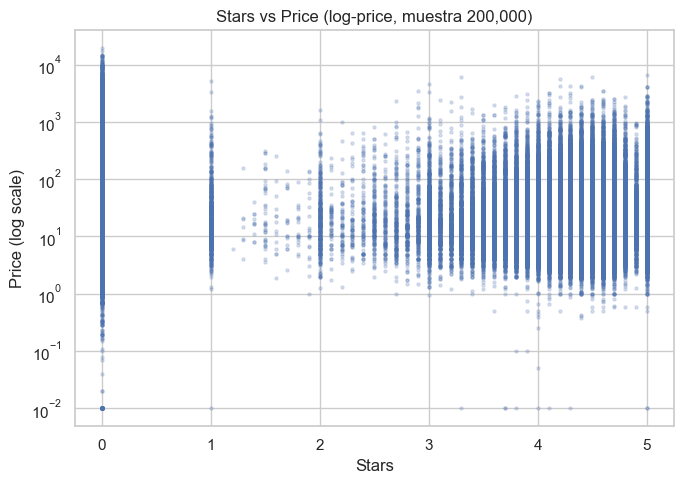

In [13]:
# Scatter de una muestra para que sea legible
sample_n = 200_000  # ajusta según tu máquina
sub_plot = df.sample(n=sample_n, random_state=42)[["price", "stars"]].dropna()

plt.figure(figsize=(7,5))
plt.scatter(sub_plot["stars"], sub_plot["price"], alpha=0.2, s=5)
plt.title(f"Stars vs Price (muestra {len(sub_plot):,})")
plt.xlabel("Stars")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

# Mismo scatter con eje Y en log para ver la cola
plt.figure(figsize=(7,5))
plt.scatter(sub_plot["stars"], sub_plot["price"], alpha=0.2, s=5)
plt.yscale("log")
plt.title(f"Stars vs Price (log-price, muestra {len(sub_plot):,})")
plt.xlabel("Stars")
plt.ylabel("Price (log scale)")
plt.tight_layout()
plt.show()


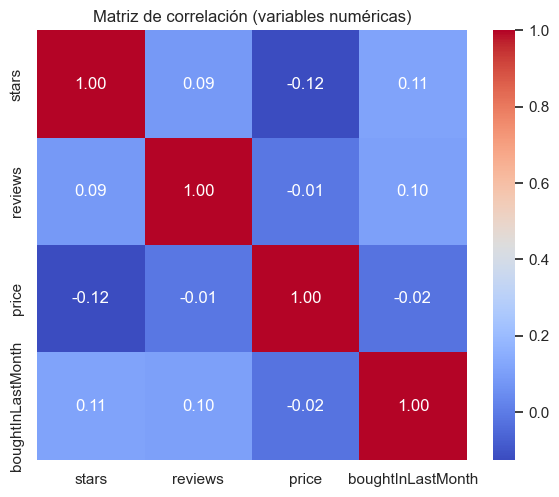

In [14]:
# Selección de columnas numéricas útiles (excluye identificadores)
num_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c.lower() not in ["uid"]]
corr = df[num_cols].corr()

plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True, cbar=True)
plt.title("Matriz de correlación (variables numéricas)")
plt.tight_layout()
plt.show()


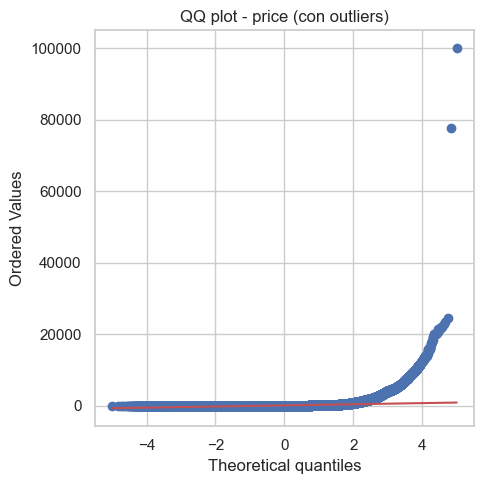

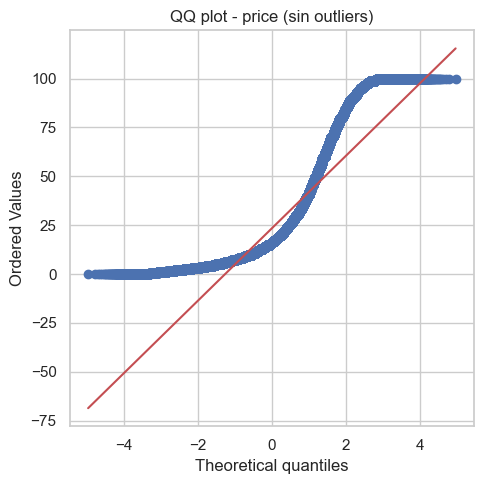

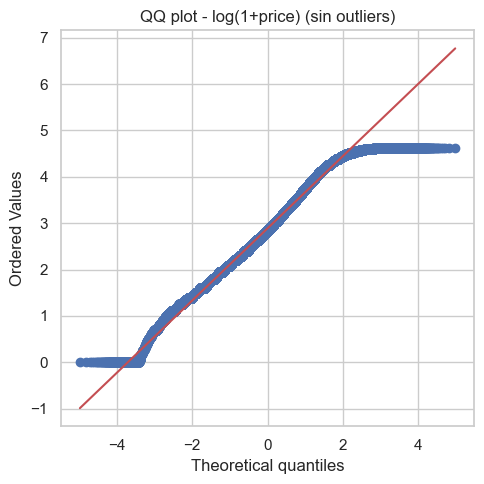

In [15]:
# Precio con y sin outliers
plt.figure(figsize=(5,5))
stats.probplot(df["price"].dropna(), dist="norm", plot=plt)
plt.title("QQ plot - price (con outliers)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(5,5))
stats.probplot(df_no_out["price"].dropna(), dist="norm", plot=plt)
plt.title("QQ plot - price (sin outliers)")
plt.tight_layout()
plt.show()

# (Opcional) QQ de log-precio
plt.figure(figsize=(5,5))
stats.probplot(np.log1p(df_no_out["price"].dropna()), dist="norm", plot=plt)
plt.title("QQ plot - log(1+price) (sin outliers)")
plt.tight_layout()
plt.show()
